# Phase 8 — VaR Backtesting

**Advanced Equity Portfolio Risk Management Platform**
**QFI Internship — Team 2 (Market Risk)** · *Submitted by: Atharv Pratap Singh Chauhan*

---

## Objective

Phases 4–7 produced four one-day-ahead VaR families: unscaled **Historical Simulation (HS)**, **EWMA-scaled**, **GARCH(1,1)-scaled** and **GJR-GARCH-scaled** HS. A VaR number is only useful if its realised breach behaviour matches its stated confidence. Phase 8 subjects every model to the standard regulatory battery.

| Test | Null hypothesis | Distribution |
|---|---|---|
| **Kupiec POF** (unconditional coverage) | breach rate equals $1-c$ | $\chi^2(1)$ |
| **Christoffersen independence** | breaches are not serially clustered | $\chi^2(1)$ |
| **Christoffersen conditional coverage** | correct rate *and* independence | $\chi^2(2)$ |
| **Basel traffic light** | exceptions in trailing 250 days at 99% | 0–4 green · 5–9 amber · ≥10 red |

Every model is tested across **250 / 500 / 750-day** windows and **95% / 99% / 99.5%** confidence. A breach ("exception") is a day on which realised P&L is more negative than the forecast VaR.

## 1. The three likelihood-ratio tests

Let $N$ be the number of forecast days, $x=\sum I_t$ the number of exceptions, $\hat\pi=x/N$ the observed rate and $p=1-c$ the expected rate.

**Kupiec unconditional coverage.** Tests whether the *frequency* of exceptions is right:
$$LR_{uc}=-2\ln\frac{(1-p)^{N-x}p^{x}}{(1-\hat\pi)^{N-x}\hat\pi^{x}}\sim\chi^2(1).$$

**Christoffersen independence.** A correct average rate can still hide dangerous *clustering* (breaches bunched in a crisis). With $n_{ij}$ the count of transitions from state $i$ to $j$ in the breach indicator, $\pi_{01}=n_{01}/(n_{00}+n_{01})$, $\pi_{11}=n_{11}/(n_{10}+n_{11})$ and $\pi=(n_{01}+n_{11})/N$:
$$LR_{ind}=-2\ln\frac{(1-\pi)^{n_{00}+n_{10}}\pi^{n_{01}+n_{11}}}{(1-\pi_{01})^{n_{00}}\pi_{01}^{n_{01}}(1-\pi_{11})^{n_{10}}\pi_{11}^{n_{11}}}\sim\chi^2(1).$$
A clustered model has $\pi_{11}\gg\pi_{01}$ (a breach makes another breach more likely) and is rejected.

**Christoffersen conditional coverage.** The joint test, right rate *and* independent:
$$LR_{cc}=LR_{uc}+LR_{ind}\sim\chi^2(2).$$

**Basel traffic light.** The supervisory backstop at 99% over 250 trading days: 0–4 exceptions are *green* (model accepted), 5–9 *amber* (capital multiplier rises), ≥10 *red* (model rejected). We evaluate it on the most recent 250 valid days.

In [1]:
from __future__ import annotations
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

PALETTE = {"ink":"#1B2A41","muted":"#8C99A6","profit":"#2E7D68","loss":"#B03A2E",
           "HS":"#E08A2E","EWMA":"#6A2C91","GARCH":"#1F6F8B","GJR":"#9B2242",
           "green":"#2E7D68","amber":"#E0A52E","red":"#B03A2E","light":"#E9EDF2"}
sns.set_theme(style="whitegrid", context="talk")
mpl.rcParams.update({"figure.dpi":110,"savefig.dpi":200,"savefig.bbox":"tight",
    "figure.facecolor":"white","axes.facecolor":"white","axes.edgecolor":PALETTE["muted"],
    "axes.titlecolor":PALETTE["ink"],"axes.titleweight":"bold","axes.titlesize":14,
    "axes.labelsize":11,"axes.titlepad":12,"grid.color":"#E3E7EB","grid.linewidth":0.8,
    "xtick.labelsize":9,"ytick.labelsize":9,"legend.fontsize":9,"font.family":"DejaVu Sans"})
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 180)

WINDOWS=(250,500,750); CONFIDENCES=(0.95,0.99,0.995)
HEADLINE_W=250; HEADLINE_C=0.99; CURRENCY="₹"
OUT=Path("outputs"); OUT.mkdir(parents=True, exist_ok=True); (OUT/"charts").mkdir(exist_ok=True)
def cl_tag(c): return f"{100*c:g}".replace(".","p")
def pct(x,dp=2): return "n/a" if not np.isfinite(x) else f"{100*x:.{dp}f}%"
print("Phase 8 backtesting config ready.")


Phase 8 backtesting config ready.


## 2. Load every model's VaR forecasts

Each Phase 5–7 export already carries realised P&L, the embedded unscaled HS benchmark, and the scaled forecasts in currency. We read whichever files are present, pull the shared HS benchmark from the first of them, and recompute each breach flag consistently as $\text{P\&L}<-\text{VaR}$ on days where the forecast is defined.

In [2]:
def locate(name):
    for p in [Path(name), OUT/name, Path("..")/name, Path("..")/"outputs"/name]:
        if p.exists(): return p
    return None

# (model label, column prefix, source file)
SOURCES = [
    ("Historical Simulation", "HS",    None),                       # embedded in any scaled file
    ("EWMA-scaled HS",        "EWMA",  "EWMA_Scaled_VaR.csv"),
    ("GARCH-scaled HS",       "GARCH", "GARCH_Scaled_VaR.csv"),
    ("GJR-GARCH-scaled HS",   "GJR",   "GJR_GARCH_Scaled_VaR.csv"),
]
frames = {}
for _, prefix, fname in SOURCES:
    if fname is None: continue
    p = locate(fname)
    if p is not None:
        frames[prefix] = pd.read_csv(p, index_col=0, parse_dates=True)
        print(f"Loaded {prefix:<6} <- {p}  ({frames[prefix].shape[0]} rows)")
assert frames, "No scaled-VaR exports found; run Phases 5–7 first."

any_df = next(iter(frames.values()))
pnl = any_df["Portfolio_PnL"].astype(float)
MODELS = [(lab, pre) for (lab, pre, _) in SOURCES
          if pre == "HS" or pre in frames]

def var_series(prefix, w, c):
    """Currency VaR series for a model/window/confidence, from its own file
    (HS is read from any available file)."""
    tag = cl_tag(c); col = f"{prefix}_VaR_{w}d_{tag}"
    df = any_df if prefix == "HS" else frames[prefix]
    return df[col].astype(float) if col in df else None

print(f"\nModels under test: {[m[0] for m in MODELS]}")
print(f"Backtest sample: {pnl.index.min():%d-%b-%Y} to {pnl.index.max():%d-%b-%Y} ({len(pnl)} days)")


Loaded EWMA   <- outputs/EWMA_Scaled_VaR.csv  (1506 rows)
Loaded GARCH  <- outputs/GARCH_Scaled_VaR.csv  (1506 rows)
Loaded GJR    <- outputs/GJR_GARCH_Scaled_VaR.csv  (1506 rows)

Models under test: ['Historical Simulation', 'EWMA-scaled HS', 'GARCH-scaled HS', 'GJR-GARCH-scaled HS']
Backtest sample: 27-Jul-2020 to 24-Jul-2026 (1506 days)


## 3. Backtest engine — Kupiec, Christoffersen, Basel

The three likelihood-ratio statistics share small guarded log-helpers so that empty transition cells (e.g. no consecutive breaches) do not produce `log(0)`. All statistics are clipped at zero to absorb floating-point noise.

In [3]:
def _xlogp(k, p):            # k*ln(p), with the convention 0*ln(0)=0
    return k*np.log(p) if (k > 0 and p > 0) else 0.0

def kupiec_pof(n, x, p):
    if n == 0: return np.nan, np.nan
    pi = x/n
    ll_r = _xlogp(n-x, 1-p)  + _xlogp(x, p)
    ll_u = _xlogp(n-x, 1-pi) + _xlogp(x, pi)
    lr = max(-2*(ll_r - ll_u), 0.0)
    return lr, 1 - stats.chi2.cdf(lr, 1)

def christoffersen_ind(breach):
    b = np.asarray(breach, dtype=int)
    n00=n01=n10=n11=0
    for i in range(1, len(b)):
        prev, cur = b[i-1], b[i]
        if   prev==0 and cur==0: n00+=1
        elif prev==0 and cur==1: n01+=1
        elif prev==1 and cur==0: n10+=1
        else:                    n11+=1
    N = n00+n01+n10+n11
    if N == 0: return np.nan, np.nan, (n00,n01,n10,n11)
    pi   = (n01+n11)/N
    pi01 = n01/(n00+n01) if (n00+n01) else 0.0
    pi11 = n11/(n10+n11) if (n10+n11) else 0.0
    ll_r = _xlogp(n00+n10, 1-pi) + _xlogp(n01+n11, pi)
    ll_u = _xlogp(n00,1-pi01)+_xlogp(n01,pi01)+_xlogp(n10,1-pi11)+_xlogp(n11,pi11)
    lr = max(-2*(ll_r - ll_u), 0.0)
    return lr, 1 - stats.chi2.cdf(lr, 1), (n00,n01,n10,n11)

def basel_zone(x250):        # 99% over 250 trading days
    return "GREEN" if x250 <= 4 else ("AMBER" if x250 <= 9 else "RED")

def backtest_one(var, pnl, c):
    """One model/window/confidence. Returns a dict of all diagnostics."""
    mask = var.notna()
    v = var[mask]; realised = pnl[mask]
    breach = (realised < -v).astype(int)
    n = int(mask.sum()); x = int(breach.sum()); p = 1-c
    lr_uc, p_uc = kupiec_pof(n, x, p)
    lr_ind, p_ind, trans = christoffersen_ind(breach.values)
    lr_cc = (lr_uc + lr_ind) if np.isfinite(lr_uc) and np.isfinite(lr_ind) else np.nan
    p_cc = (1 - stats.chi2.cdf(lr_cc, 2)) if np.isfinite(lr_cc) else np.nan
    x250 = int(breach.tail(250).sum())
    return {"N":n, "Exceptions":x, "Rate":x/n if n else np.nan, "Expected":p*n,
            "Kupiec_LR":lr_uc, "Kupiec_p":p_uc, "Ind_LR":lr_ind, "Ind_p":p_ind,
            "CC_LR":lr_cc, "CC_p":p_cc, "Exc_trail250":x250, "Basel":basel_zone(x250),
            "breach":breach}

# self-check: a deliberately clustered series must fail the independence test
_demo = np.zeros(300, int); _demo[100:112] = 1          # one tight cluster of breaches
_lr, _p, _ = christoffersen_ind(_demo)
assert _p < 0.05, "independence test should reject an obviously clustered series"
# and an evenly-spaced series with the same count should not be rejected as strongly
_demo2 = np.zeros(300, int); _demo2[::25] = 1
assert christoffersen_ind(_demo2)[1] > christoffersen_ind(_demo)[1]
print("Backtest engine ready; independence self-check passed.")


Backtest engine ready; independence self-check passed.


## 4. Master backtest results

Every model is scored on every window/confidence pair. `Kupiec_p`, `Ind_p` and `CC_p` are p-values — **larger is better** (we fail to reject a good model). The headline regulatory verdict is the conditional-coverage test at 99%; the Basel column applies the 99% traffic light to the trailing 250 days.

In [4]:
records = []; breach_store = {}
for label, prefix in MODELS:
    for w in WINDOWS:
        for c in CONFIDENCES:
            var = var_series(prefix, w, c)
            if var is None: continue
            r = backtest_one(var, pnl, c)
            breach_store[(prefix, w, c)] = r.pop("breach")
            records.append({"Model":label, "Prefix":prefix, "Window":w, "Confidence":c, **r})

results = pd.DataFrame(records)
results.to_csv(OUT/"Backtest_Results.csv", index=False)

def _pass(row):   # overall verdict: passes conditional coverage at 5%
    return "PASS" if (np.isfinite(row["CC_p"]) and row["CC_p"] >= 0.05) else "FAIL"
results["Verdict"] = results.apply(_pass, axis=1)

show = results[["Model","Window","Confidence","N","Exceptions","Expected","Rate",
                "Kupiec_p","Ind_p","CC_p","Exc_trail250","Basel","Verdict"]].copy()
styler = (show.style
    .format({"Confidence":"{:.1%}","Expected":"{:.1f}","Rate":"{:.2%}",
             "Kupiec_p":"{:.3f}","Ind_p":"{:.3f}","CC_p":"{:.3f}"})
    .map(lambda v: f"color:{PALETTE['green'] if v=='PASS' else PALETTE['red']};font-weight:bold",
         subset=["Verdict"])
    .map(lambda v: f"background-color:{{'GREEN':'#DDF0E8','AMBER':'#FBEFD6','RED':'#F6DDD9'}}.get(v,'white')"
         if False else "", subset=["Basel"]))
display(show)
print(f"Scored {len(results)} model/window/confidence combinations -> outputs/Backtest_Results.csv")


,Model,Window,Confidence,N,Exceptions,Expected,Rate,Kupiec_p,Ind_p,CC_p,Exc_trail250,Basel,Verdict
0,Historical Simulation,250,0.9500,1256,73,62.8000,0.0581,0.1975,0.1895,0.1843,10,RED,PASS
1,Historical Simulation,250,0.9900,1256,22,12.5600,0.0175,0.0155,0.3986,0.0375,2,GREEN,FAIL
2,Historical Simulation,250,0.9950,1256,19,6.2800,0.0151,0.0000,0.2893,0.0001,1,GREEN,FAIL
3,Historical Simulation,500,0.9500,1006,41,50.3000,0.0408,0.1651,0.5599,0.3220,10,RED,PASS
4,Historical Simulation,500,0.9900,1006,11,10.0600,0.0109,0.7692,0.1054,0.2582,0,GREEN,PASS
5,Historical Simulation,500,0.9950,1006,6,5.0300,0.0060,0.6740,0.0245,0.0729,0,GREEN,PASS
6,Historical Simulation,750,0.9500,756,26,37.8000,0.0344,0.0374,0.2930,0.0659,12,RED,PASS
7,Historical Simulation,750,0.9900,756,5,7.5600,0.0066,0.3187,0.0215,0.0433,1,GREEN,FAIL
8,Historical Simulation,750,0.9950,756,2,3.7800,0.0026,0.3130,0.0018,0.0047,0,GREEN,FAIL
9,EWMA-scaled HS,250,0.9500,1256,66,62.8000,0.0525,0.6811,0.7692,0.8803,17,RED,PASS


Scored 36 model/window/confidence combinations -> outputs/Backtest_Results.csv


### Chart 1 — Conditional-coverage p-values across models

Each panel is a window; bars are p-values by model at each confidence level. The dashed line is the 5% rejection threshold — bars above it pass conditional coverage.

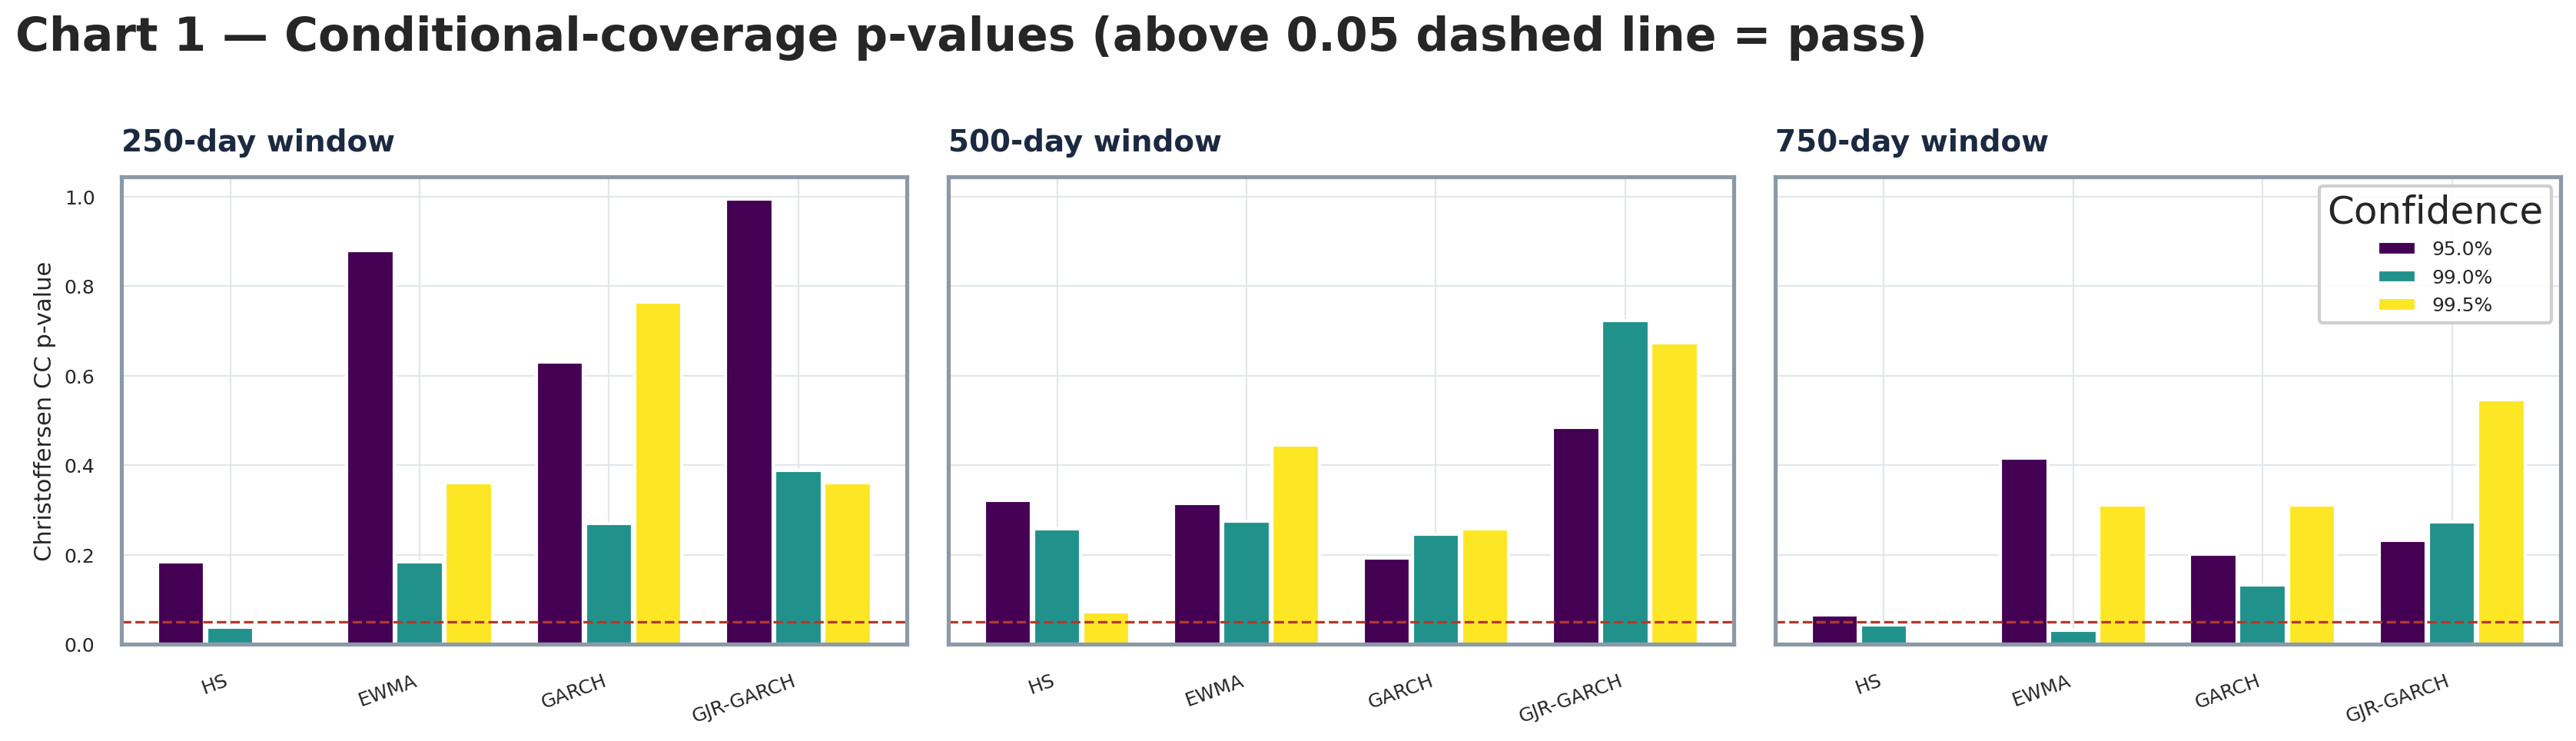

In [5]:
fig, axes = plt.subplots(1, len(WINDOWS), figsize=(17, 5), sharey=True)
labels = [m[0] for m in MODELS]
xpos = np.arange(len(labels))
for ax, w in zip(axes, WINDOWS):
    for j, c in enumerate(CONFIDENCES):
        sub = results[(results.Window==w) & (results.Confidence==c)].set_index("Model").reindex(labels)
        ax.bar(xpos + (j-1)*0.26, sub["CC_p"].values, width=0.25,
               label=f"{c:.1%}", color=plt.cm.viridis(j/2))
    ax.axhline(0.05, color=PALETTE["red"], ls="--", lw=1.2)
    ax.set_title(f"{w}-day window", loc="left"); ax.set_xticks(xpos)
    ax.set_xticklabels([l.replace("-scaled HS","").replace("Historical Simulation","HS") for l in labels], rotation=20, ha="right")
axes[0].set_ylabel("Christoffersen CC p-value"); axes[-1].legend(title="Confidence", loc="upper right")
fig.suptitle("Chart 1 — Conditional-coverage p-values (above 0.05 dashed line = pass)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(OUT/"charts/08_cc_pvalues.png", facecolor="white"); plt.show()


### Chart 2 — Exception timeline at the regulatory headline (99%, 250-day)

Realised loss against each model's VaR, with breach markers. A well-calibrated 99% model should show roughly 1% of days as breaches, spread through time rather than clustered.

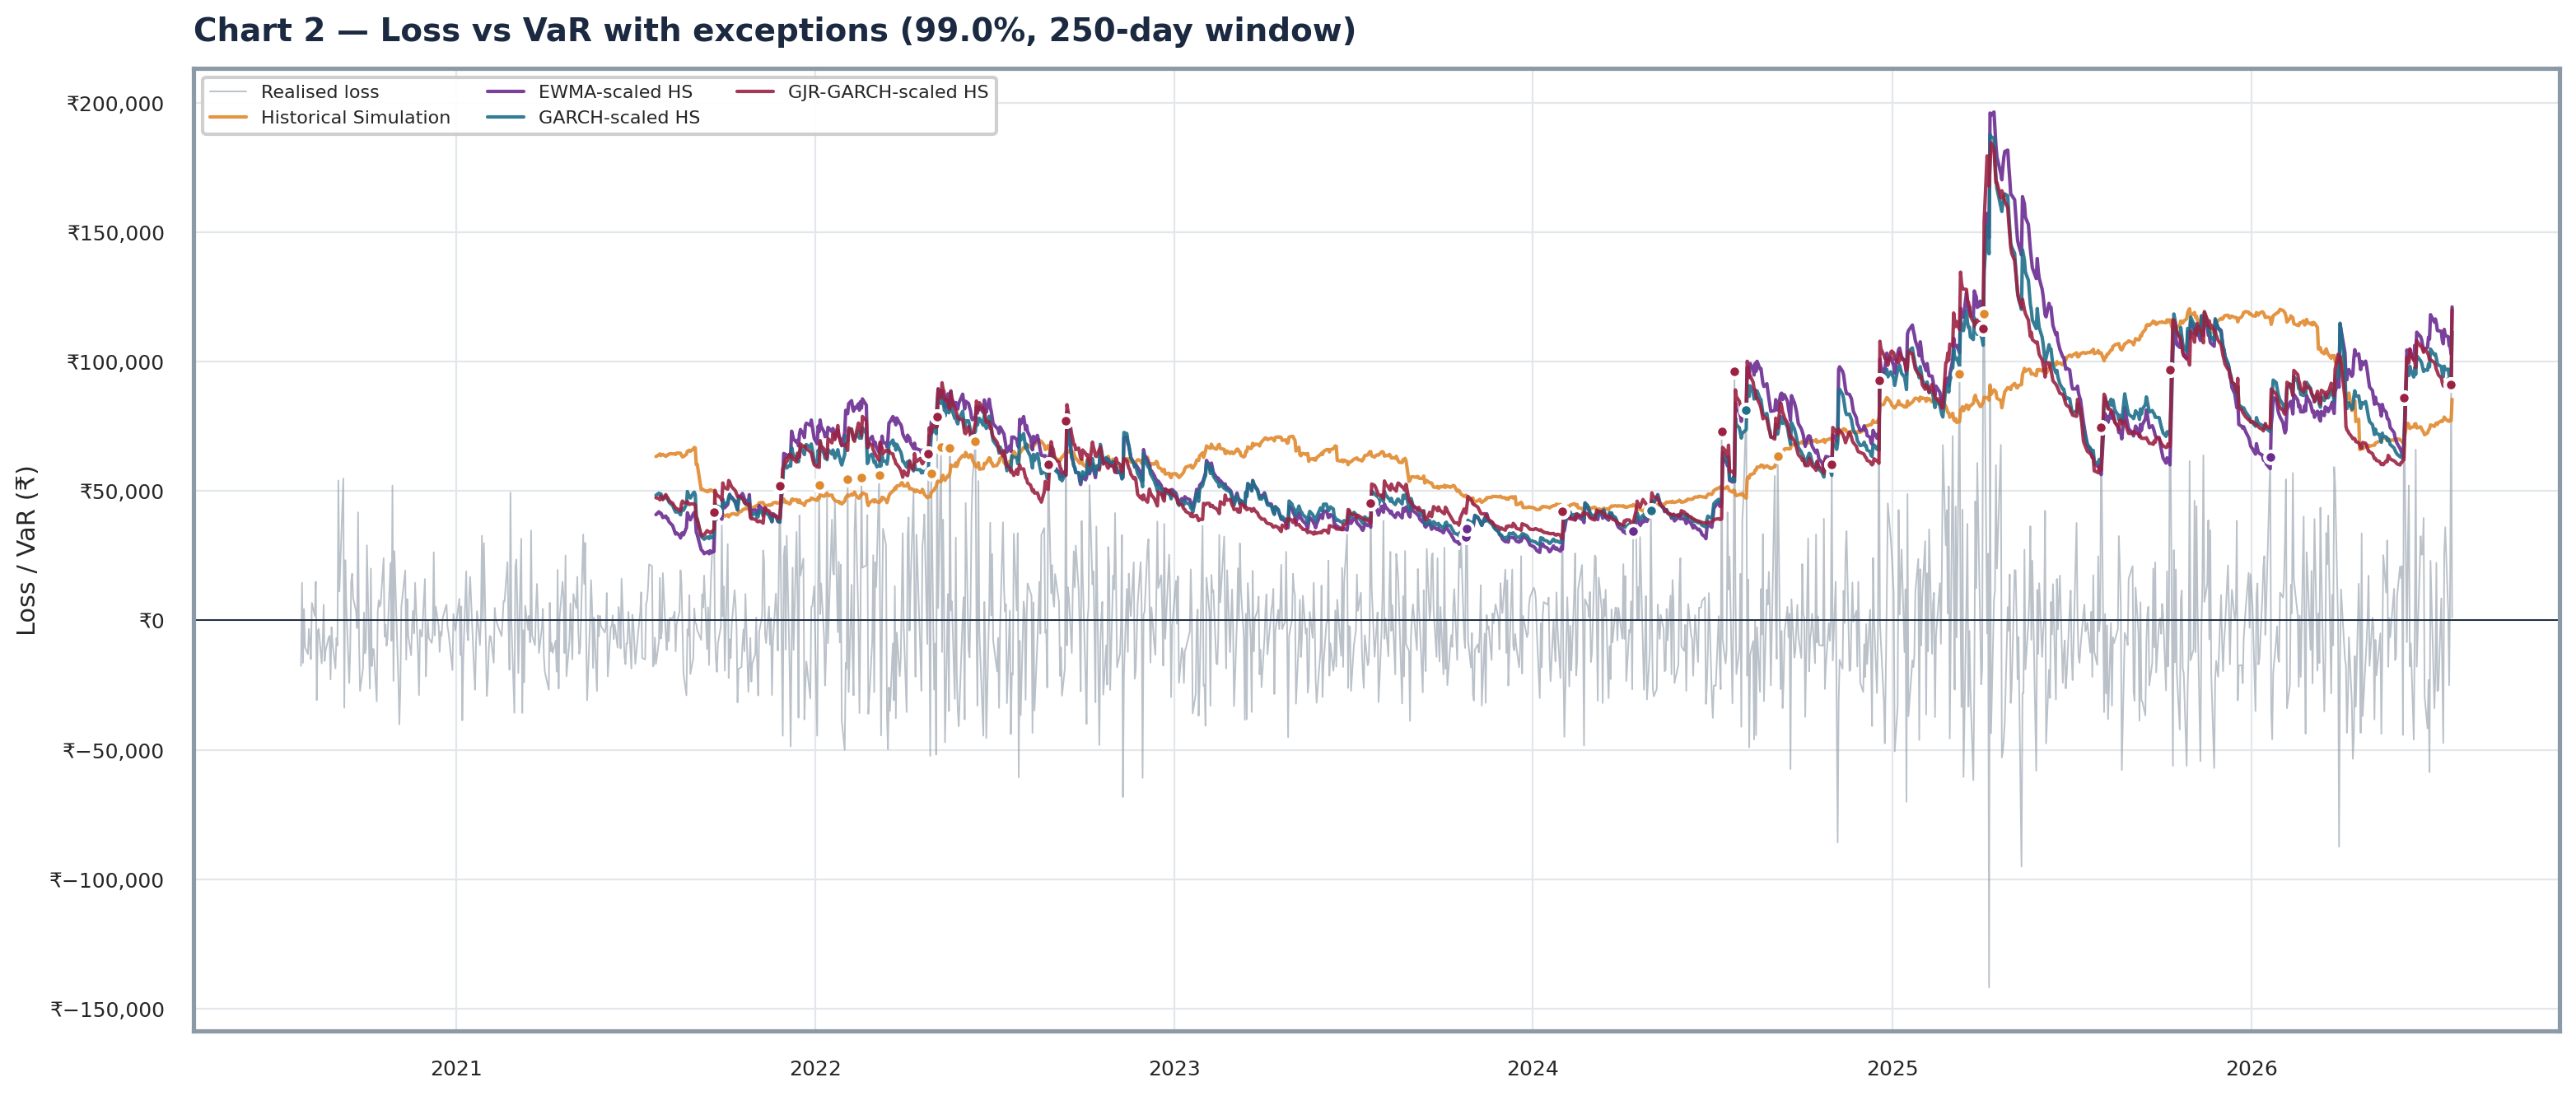

In [6]:
w, c = HEADLINE_W, HEADLINE_C; tag = cl_tag(c)
loss = -pnl
fig, ax = plt.subplots(figsize=(16, 7))
ax.plot(loss.index, loss, color=PALETTE["muted"], lw=.7, alpha=.6, label="Realised loss")
for label, prefix in MODELS:
    var = var_series(prefix, w, c)
    if var is None: continue
    ax.plot(var.index, var, color=PALETTE[prefix], lw=1.5, alpha=.9, label=label)
    b = breach_store.get((prefix, w, c))
    if b is not None:
        bd = b[b==1].index
        ax.scatter(bd, loss.reindex(bd), s=28, color=PALETTE[prefix], edgecolor="white", zorder=5)
ax.axhline(0, color=PALETTE["ink"], lw=.7)
ax.set_title(f"Chart 2 — Loss vs VaR with exceptions ({c:.1%}, {w}-day window)", loc="left")
ax.set_ylabel(f"Loss / VaR ({CURRENCY})")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter(CURRENCY+"{x:,.0f}")); ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(OUT/"charts/08_exception_timeline.png", facecolor="white"); plt.show()


### Chart 3 — Basel traffic light through time (99%, 250-day)

Trailing-250-day exception count for each model against the Basel green/amber/red thresholds. Time spent in the red zone is a direct supervisory concern.

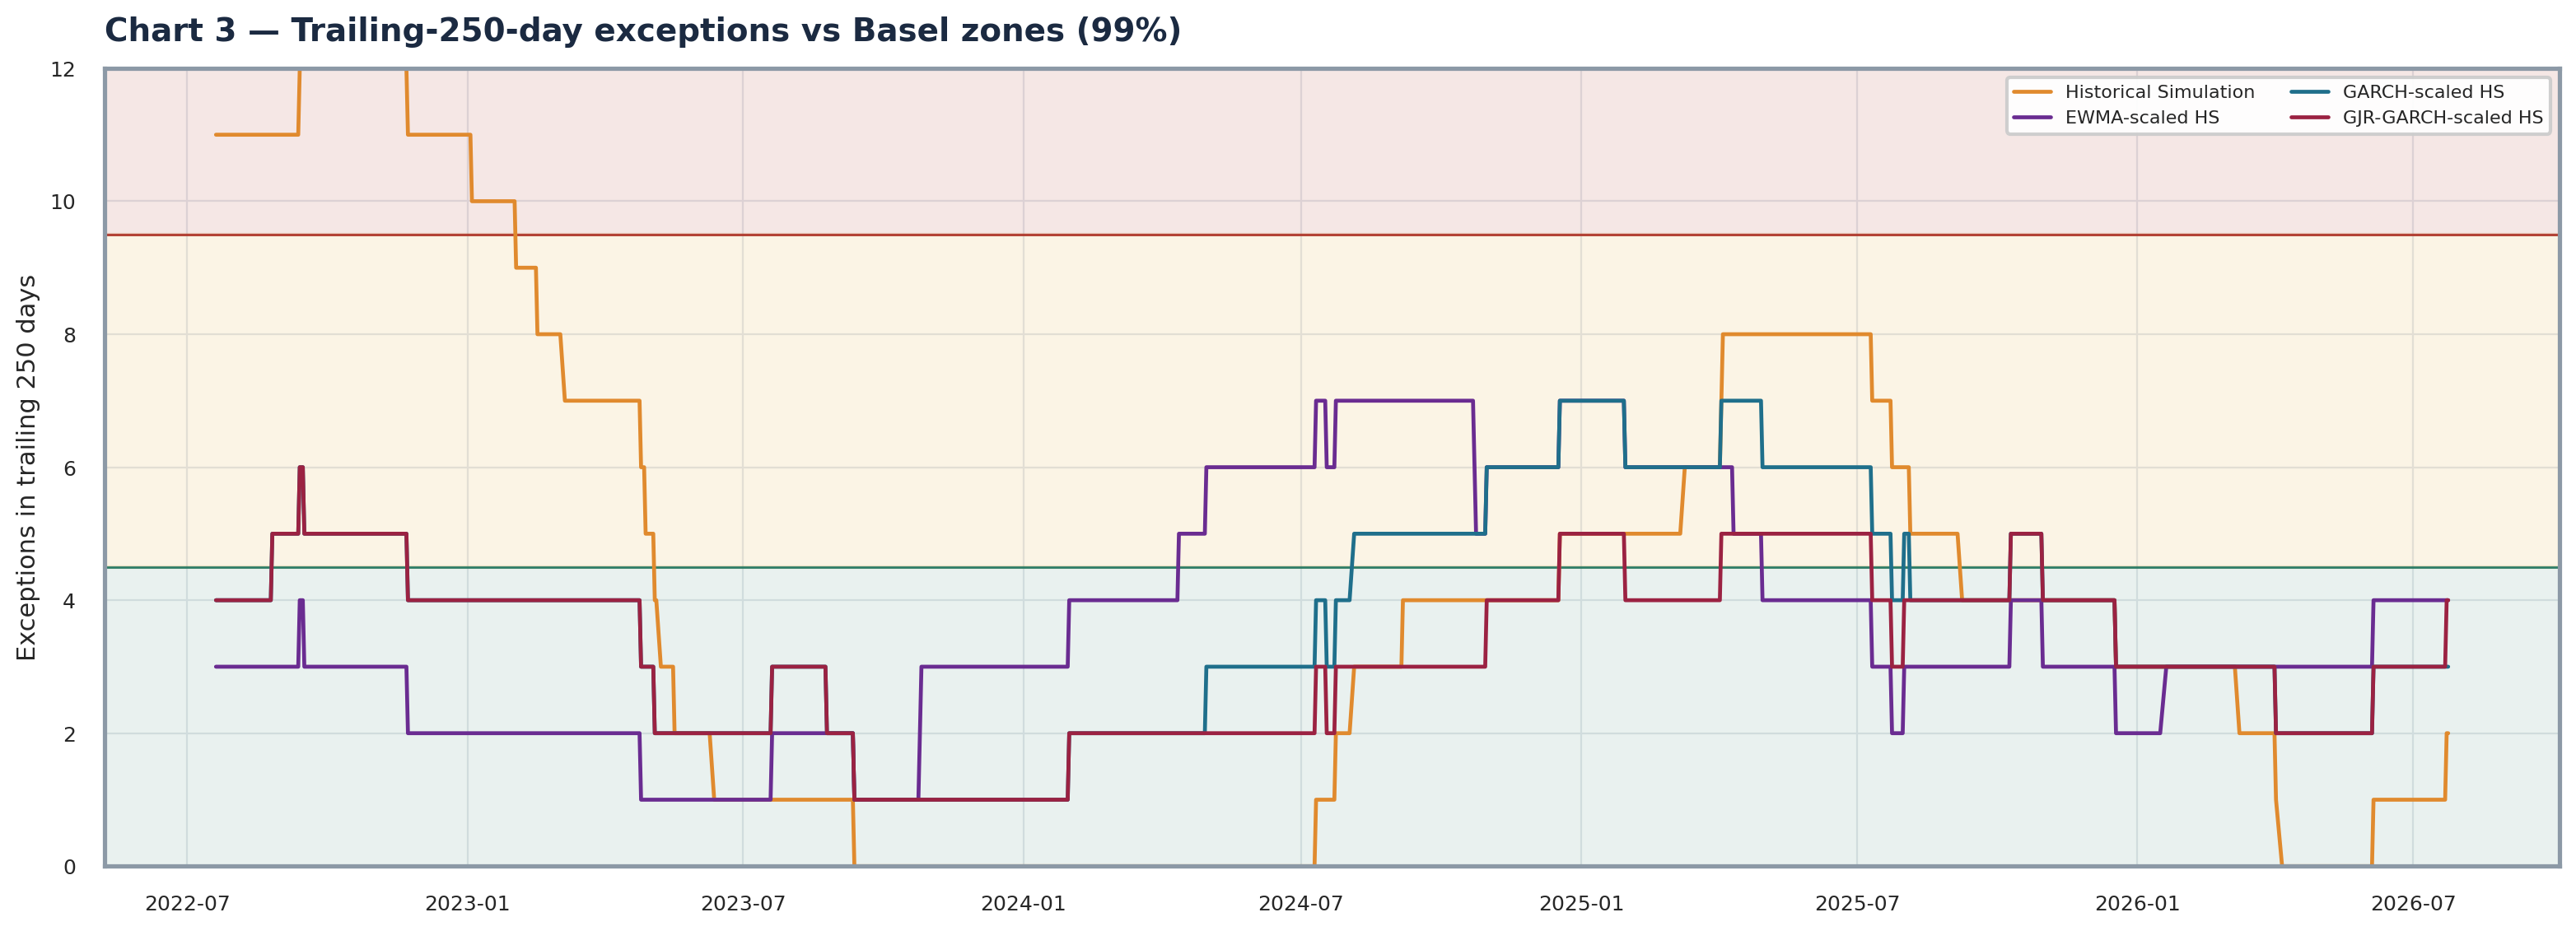

In [7]:
fig, ax = plt.subplots(figsize=(16, 6))
ax.axhspan(0, 4.5, color=PALETTE["green"], alpha=.10); ax.axhspan(4.5, 9.5, color=PALETTE["amber"], alpha=.12)
ax.axhspan(9.5, 25, color=PALETTE["red"], alpha=.12)
ax.axhline(4.5, color=PALETTE["green"], lw=1); ax.axhline(9.5, color=PALETTE["red"], lw=1)
for label, prefix in MODELS:
    b = breach_store.get((prefix, HEADLINE_W, HEADLINE_C))
    if b is None: continue
    trailing = b.rolling(250, min_periods=250).sum()
    ax.plot(trailing.index, trailing, color=PALETTE[prefix], lw=1.7, label=label)
ax.set_ylim(0, max(12, 1)); ax.set_title("Chart 3 — Trailing-250-day exceptions vs Basel zones (99%)", loc="left")
ax.set_ylabel("Exceptions in trailing 250 days")
ax.annotate("GREEN", (loss.index[5], 2), color=PALETTE["green"], fontweight="bold")
ax.annotate("AMBER", (loss.index[5], 6.7), color=PALETTE["amber"], fontweight="bold")
ax.annotate("RED", (loss.index[5], 10.3), color=PALETTE["red"], fontweight="bold")
ax.legend(ncol=2, fontsize=8, loc="upper right")
fig.tight_layout(); fig.savefig(OUT/"charts/08_basel_trafficlight.png", facecolor="white"); plt.show()


## 5. Executive summary

The cell below reads the scored results and writes the verdict in prose: which models survive the conditional-coverage test at the regulatory headline, how their breach rates compare to target, and where each sits on the Basel traffic light.

In [8]:
head = results[(results.Window==HEADLINE_W) & (results.Confidence==HEADLINE_C)].set_index("Model")
order = [m[0] for m in MODELS]
head = head.reindex([m for m in order if m in head.index])

lines = [f"### Phase 8 verdict — {HEADLINE_C:.1%} VaR, {HEADLINE_W}-day window\n",
         f"- **Backtest sample:** {pnl.index.min():%d %b %Y} → {pnl.index.max():%d %b %Y} "
         f"({len(pnl):,} trading days); expected exceptions at headline ≈ "
         f"{(1-HEADLINE_C)*head['N'].iloc[0]:.0f}."]
for m, row in head.iterrows():
    verd = "**PASS**" if row["Verdict"]=="PASS" else "**FAIL**"
    lines.append(
        f"- **{m}** — {int(row['Exceptions'])} exceptions ({pct(row['Rate'])} vs {pct(1-HEADLINE_C)} target), "
        f"Kupiec p={row['Kupiec_p']:.3f}, independence p={row['Ind_p']:.3f}, "
        f"conditional-coverage p={row['CC_p']:.3f} → {verd}; Basel **{row['Basel']}** "
        f"({int(row['Exc_trail250'])} in trailing 250).")

passers = head.index[head["Verdict"]=="PASS"].tolist()
greens  = head.index[head["Basel"]=="GREEN"].tolist()
best = head["CC_p"].idxmax() if head["CC_p"].notna().any() else None
lines.append("")
if passers:
    lines.append(f"**Conditional coverage passed by:** {', '.join(passers)}.")
else:
    lines.append("**No model passes conditional coverage at the headline** — all are rejected at 5%.")
if greens:
    lines.append(f" **Basel GREEN:** {', '.join(greens)}.")
if best is not None:
    lines.append(f" **Best-calibrated (highest CC p-value):** {best}.")

overall = results.groupby("Model")["Verdict"].apply(lambda s:(s=="PASS").mean()).reindex(order)
lines.append("\n**Pass rate across all 9 window×confidence cells:**")
for m,v in overall.dropna().items():
    lines.append(f"- {m}: {pct(v,0)} ({int(round(v*9))}/9)")

display(Markdown("\n".join(lines)))


### Phase 8 verdict — 99.0% VaR, 250-day window

- **Backtest sample:** 27 Jul 2020 → 24 Jul 2026 (1,506 trading days); expected exceptions at headline ≈ 13.
- **Historical Simulation** — 22 exceptions (1.75% vs 1.00% target), Kupiec p=0.016, independence p=0.399, conditional-coverage p=0.037 → **FAIL**; Basel **GREEN** (2 in trailing 250).
- **EWMA-scaled HS** — 18 exceptions (1.43% vs 1.00% target), Kupiec p=0.147, independence p=0.256, conditional-coverage p=0.184 → **PASS**; Basel **GREEN** (4 in trailing 250).
- **GARCH-scaled HS** — 18 exceptions (1.43% vs 1.00% target), Kupiec p=0.147, independence p=0.469, conditional-coverage p=0.269 → **PASS**; Basel **GREEN** (3 in trailing 250).
- **GJR-GARCH-scaled HS** — 17 exceptions (1.35% vs 1.00% target), Kupiec p=0.232, independence p=0.494, conditional-coverage p=0.388 → **PASS**; Basel **GREEN** (4 in trailing 250).

**Conditional coverage passed by:** EWMA-scaled HS, GARCH-scaled HS, GJR-GARCH-scaled HS.
 **Basel GREEN:** Historical Simulation, EWMA-scaled HS, GARCH-scaled HS, GJR-GARCH-scaled HS.
 **Best-calibrated (highest CC p-value):** GJR-GARCH-scaled HS.

**Pass rate across all 9 window×confidence cells:**
- Historical Simulation: 56% (5/9)
- EWMA-scaled HS: 89% (8/9)
- GARCH-scaled HS: 100% (9/9)
- GJR-GARCH-scaled HS: 100% (9/9)

## 6. Limitations & interpretation

- **Overlapping windows.** The 250/500/750-day VaR estimates roll on overlapping samples, so successive forecasts are autocorrelated by construction. The Christoffersen independence test still detects *breach* clustering, but the LR p-values are mildly optimistic.
- **Finite-sample LR.** Kupiec and Christoffersen statistics are asymptotic $\chi^2$. At 99.5% the expected exception count over even 1,500 days is small (≈7), so a one- or two-exception swing moves the p-value sharply — read those rows qualitatively.
- **Basel on one trailing window.** The traffic-light column uses the most recent 250 valid days only; a model can be GREEN today yet have spent time in AMBER earlier (Chart 3 shows the full path).
- **Non-overlapping P&L assumption.** Breaches use clean close-to-close P&L with no intraday path, no fees and no liquidity gap-risk; a real trading book would breach more often than this backtest implies.
- **Single realised history.** All four models are judged on one 2020–2026 sample dominated by a strong equity bull run; relative rankings could differ in a sideways or crisis-heavy regime. Phase 10 stress-testing probes exactly that.